## Quiz 2. Simulacion en Python

## Esteban Garcia Otalvaro
## CC.1001446658

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy import signal
from scipy.signal import TransferFunction, lti, step

In [10]:
# Parámetros del sistema (dados en el enunciado)
ta = 0.02   #absorción (s)
te = 12    # Tiempo de eliminacion (s)
td = 5   # Tiempo de distribución (s)

# Vector de tiempo de simulación (20 s)
t = np.linspace(0, 25, 3000)  # 2000 puntos de tiempo entre 0 y 20 segundos


El paciente 1 tiene una mayor tasa de concentración al final de la prueba.


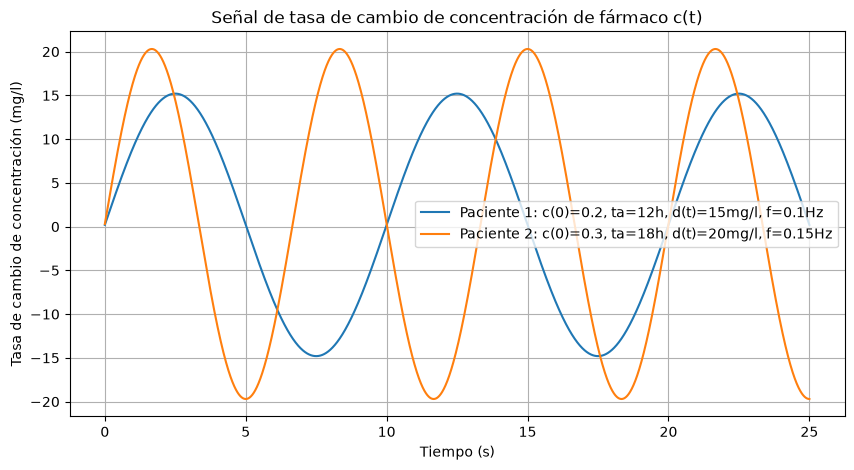

In [16]:
#Método 1: Solución mediante ecuaciones diferenciales (espacio de estados)
# Definimos x1 = d, x2 = dc/dt usadno solve_ivp
def sistema_ode(d, t, ta, te, td):
    c, dV = d
    c_actual = concentracion_escalon(t)
    ddV = te*(td + te * dV + 1 / ta) / I
    return [dV, ddV]


#Método 2: Solución mediante función de transferencia
num = [1]
den = [60, 144, 1 / ta]
sistema_tf = signal.TransferFunction(num, den)


#obtener señal de tasa de cambio de concentracion de farmaco c(t) para paciente 1 y paciente 2

#Punto 2

tasa_cambio_paciente1 = 15 * np.sin(2 * np.pi * 0.1 * t) + 0.2
tasa_cambio_paciente2 = 20 * np.sin(2 * np.pi * 0.15 * t) + 0.3


def concentracion_inicial(t):
    if t < 0:
        return 0
    elif t < 5:
        return 15 * np.sin(2 * np.pi * 0.1 * t) + 0.2
    else:
        return 20 * np.sin(2 * np.pi * 0.15 * t) + 0.3



#Punto 3
#Graficar la señal de tasa de cambio de concentración para paciente 1 y paciente 2
plt.figure(figsize=(10, 5))
plt.plot(t, tasa_cambio_paciente1, label='Paciente 1: c(0)=0.2, ta=12h, d(t)=15mg/l, f=0.1Hz')
plt.plot(t, tasa_cambio_paciente2, label='Paciente 2: c(0)=0.3, ta=18h, d(t)=20mg/l, f=0.15Hz')
plt.title('Señal de tasa de cambio de concentración de fármaco c(t)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Tasa de cambio de concentración (mg/l)')
plt.legend()
plt.grid()

##Punto 4
#Paciente con mayor tasa de concentracion al final de la prueba de 25 segundos
concentracion_final_paciente1 = tasa_cambio_paciente1[-1]
concentracion_final_paciente2 = tasa_cambio_paciente2[-1]

#Comparar las concentraciones finales de los pacientes
if concentracion_final_paciente1 > concentracion_final_paciente2:
    print("El paciente 1 tiene una mayor tasa de concentración al final de la prueba.")
else:
    print("El paciente 2 tiene una mayor tasa de concentración al final de la prueba.")





